# Part 3C：样本外有效性（Out-of-sample effectiveness）

> 组内工作 notebook。说明文字用中文；**图表、表格的文字用英文**，可以直接放进报告。

## 题目在问什么

3A 的三组权重**保持不变**，换成优化器**没见过**的 **2005/01 – 2023/07**（223 个月）数据，计算各自实现的年化波动率：

- 哪个组合的实现波动率最低、哪个最高？
- 这个顺序是否"符合预期"？结合课上讲的优化内容，为什么会这样？

**直观理解**：3B 是开卷考试（用估计权重的同一段数据来检验），3C 是**闭卷考试**。站在 2004 年底定好权重，之后 18 年半不再改动，看它在真实的未来里能不能真的压低波动。

## 计算方法（与 3B 完全相同，只换时间段）

1. 每月组合收益 $r_{p,t} = w^\top r_t$，$w$ 固定为 3A 的权重（每月调回目标权重，不重新估计）；
2. 年化波动率 = 月收益样本标准差 × $\sqrt{12}$。

## 本 notebook 的输出

| 文件 | 内容 |
|---|---|
| `output/tables/tab_3C_oos_vol.csv` | 样本内、样本外波动率及两者的比值 |
| `output/tables/tab_3C_subperiod_vol.csv` | 分时段稳健性检查 |
| `output/figures/fig_3C_oos_vol.png` | 报告主图：样本内 vs 样本外波动率 |
| `output/figures/fig_3C_rolling_vol.png` | 辅助图：滚动 36 个月波动率 |

## 目录

1. 环境设置 · 2. 读取数据与 3A 权重 · 3. 样本外波动率 · 4. 与样本内对比：优化"打了多少折" · 5. 参照组 · 6. 为什么排序变了 · 7. 稳健性：分时段 · 8. 报告用图表 · 9. 写报告时的要点

## 1. 环境设置

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

HERE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "part3_common.py").exists()
            or (p / "part3" / "python_source" / "part3_common.py").exists())
if not (HERE / "part3_common.py").exists():
    HERE = HERE / "part3" / "python_source"
sys.path.insert(0, str(HERE))
import part3_common as p3
from part3_common import config, utils, COLS, CN, EN

config.apply_style()
print("样本内（种子期）:", config.PERIODS["3_seed"])
print("样本外          :", config.PERIODS["3C"])

样本内（种子期）: ('1995-01', '2004-12')
样本外          : ('2005-01', '2023-07')


## 2. 读取数据与 3A 权重

In [2]:
rets = p3.load_industry_returns()
W = p3.load_weights_3A()
ins = utils.select_period(rets, "3_seed")
oos = utils.select_period(rets, "3C")

print(f"样本内: {ins.index[0]} ~ {ins.index[-1]}，{len(ins)} 个月")
print(f"样本外: {oos.index[0]} ~ {oos.index[-1]}，{len(oos)} 个月")
assert len(ins) == 120 and len(oos) == 223
assert ins.index.max() < oos.index.min(), "样本内与样本外不能重叠"
print("两段不重叠 ✓；3A 权重合计:", W.sum().round(6).tolist())

样本内: 1995-01 ~ 2004-12，120 个月
样本外: 2005-01 ~ 2023-07，223 个月
两段不重叠 ✓；3A 权重合计: [1.0, 1.0, 1.0]


## 3. 样本外波动率（题目要的核心数字）

In [3]:
R_in = p3.portfolio_returns(ins, W)
R_oos = p3.portfolio_returns(oos, W)
vol_in = R_in.apply(utils.annualized_volatility)
vol_oos = R_oos.apply(utils.annualized_volatility)

res = pd.DataFrame({"样本外年化波动率": vol_oos,
                    "样本外排名（1 = 最低）": vol_oos.rank().astype(int)}).rename(index=COLS)
print(res.sort_values("样本外年化波动率").to_string(formatters={"样本外年化波动率": "{:.2%}".format}))

                         样本外年化波动率  样本外排名（1 = 最低）
Min-var (long-only)        14.29%              1
Min-var (shorts allowed)   16.75%              2
Inverse volatility         17.23%              3


## 4. 与样本内对比：优化"打了多少折"

把 3B 的样本内结果放在旁边，看两件事：

- **排名有没有变**；
- **样本外 / 样本内 的比值**：比值越大，说明样本内的数字"水分"越多，组合越依赖于对历史数据的拟合。

In [4]:
cmp = pd.DataFrame({
    "样本内 1995–2004": vol_in,
    "样本外 2005–2023": vol_oos,
    "样本外 / 样本内": vol_oos / vol_in,
    "样本内排名": vol_in.rank().astype(int),
    "样本外排名": vol_oos.rank().astype(int),
}).rename(index=COLS)
cmp.style.format({"样本内 1995–2004": "{:.2%}", "样本外 2005–2023": "{:.2%}", "样本外 / 样本内": "{:.2f}×"})

,样本内 1995–2004,样本外 2005–2023,样本外 / 样本内,样本内排名,样本外排名
Min-var (shorts allowed),7.59%,16.75%,2.21×,1,2
Min-var (long-only),10.32%,14.29%,1.39×,2,1
Inverse volatility,13.99%,17.23%,1.23×,3,3


## 5. 参照组（与 3B 相同，用来给数字一个尺度）

- **49 个行业等权组合**：每月调回 1/49；
- **样本内波动最低的单个行业**：用 1995–2004 的数据选出（是食品行业），之后一直持有。这个参照组同样只用了 2004 年底以前的信息，和三个组合比较是公平的。

不想放进报告的话，把 `SHOW_REFERENCE` 改成 `False` 再重跑。

In [5]:
SHOW_REFERENCE = True

low_ind = ins.apply(utils.annualized_volatility).idxmin()      # 用样本内选出
REF = {
    "Equal weight (49 industries)": (ins.mean(axis=1), oos.mean(axis=1)),
    f"Lowest-vol industry in 1995–2004 ({EN[low_ind]})": (ins[low_ind], oos[low_ind]),
}
ref = pd.DataFrame({k: {"样本内 1995–2004": utils.annualized_volatility(a),
                        "样本外 2005–2023": utils.annualized_volatility(b)} for k, (a, b) in REF.items()}).T
ref["样本外 / 样本内"] = ref["样本外 2005–2023"] / ref["样本内 1995–2004"]
print(ref.to_string(formatters={"样本内 1995–2004": "{:.2%}".format, "样本外 2005–2023": "{:.2%}".format,
                                "样本外 / 样本内": "{:.2f}×".format}))

oos_ind = oos.apply(utils.annualized_volatility)
print(f"\n样本外单个行业波动率：最低 {oos_ind.min():.1%}（{oos_ind.idxmin()} {CN[oos_ind.idxmin()]}），"
      f"中位数 {oos_ind.median():.1%}")

table = pd.concat([cmp.iloc[:, :3], ref])
table.columns = ["In-sample vol (Jan 1995 - Dec 2004)", "Out-of-sample vol (Jan 2005 - Jul 2023)", "Ratio OOS / IS"]
table["Type"] = ["3A portfolio"] * 3 + ["Reference"] * len(ref)
table.index.name = "Portfolio"
print("\nCSV →", utils.save_table(table, "tab_3C_oos_vol", float_format="%.6f").relative_to(p3.ROOT))

                                                 样本内 1995–2004 样本外 2005–2023 样本外 / 样本内
Equal weight (49 industries)                            14.63%        17.45%     1.19×
Lowest-vol industry in 1995–2004 (Food products)        15.18%        12.68%     0.83×

样本外单个行业波动率：最低 12.7%（Food 食品），中位数 21.8%



CSV → output/tables/tab_3C_oos_vol.csv


## 6. 为什么排序变了：拆开看

### 6.1 可做空组合：被估计误差"放大"

可做空组合在样本内靠大量多空对冲把波动压到 7.6%。下面看它的**杠杆**有多大，以及它押注的那些对冲关系在样本外还剩多少。这里用"多头合计与空头合计之间的相关性"来衡量对冲效果：相关性越高，空头越能抵消多头的波动。

In [6]:
w = W["mv_short"]
long_leg, short_leg = w.clip(lower=0), (-w).clip(lower=0)
print(f"多头合计 {long_leg.sum():.0%}，空头合计 {short_leg.sum():.0%}，总杠杆（多+空）{long_leg.sum() + short_leg.sum():.1f} 倍")

for name, df in [("样本内", ins), ("样本外", oos)]:
    L = df[w.index] @ (long_leg / long_leg.sum())         # 多头部分（归一化为 100%）
    S = df[w.index] @ (short_leg / short_leg.sum())       # 空头部分（归一化为 100%）
    print(f"{name}: 多头腿与空头腿的相关性 = {L.corr(S):.3f}，"
          f"多头腿波动 {utils.annualized_volatility(L):.1%}，空头腿波动 {utils.annualized_volatility(S):.1%}")

多头合计 284%，空头合计 184%，总杠杆（多+空）4.7 倍
样本内: 多头腿与空头腿的相关性 = 0.980，多头腿波动 11.9%，空头腿波动 16.1%
样本外: 多头腿与空头腿的相关性 = 0.965，多头腿波动 16.6%，空头腿波动 18.6%


### 6.2 市场环境也变了：行业之间的相关性上升

协方差矩阵并不是固定不变的。2005–2023 年经历了 2008 年金融危机和 2020 年新冠疫情，危机时各行业往往一起下跌，平均相关性明显上升。这会削弱所有分散化策略的效果，也是三个组合的样本外波动普遍比样本内高的原因之一。

In [7]:
def avg_corr(df):
    c = df.corr().to_numpy()
    return c[np.triu_indices_from(c, 1)].mean()

print(f"行业两两相关系数的平均值：样本内 {avg_corr(ins):.2f} → 样本外 {avg_corr(oos):.2f}")
print(f"单个行业波动率的中位数    ：样本内 {ins.apply(utils.annualized_volatility).median():.1%} → "
      f"样本外 {oos.apply(utils.annualized_volatility).median():.1%}")

行业两两相关系数的平均值：样本内 0.40 → 样本外 0.59
单个行业波动率的中位数    ：样本内 21.9% → 样本外 21.8%


## 7. 稳健性：分时段看排序是否一致

样本外长达 18 年半，其中包含 2008 年金融危机。如果排序只是被某一段危机"带偏"了，结论就不可靠。下面把样本外切成几段分别计算，看排序是否在各段都成立。

In [8]:
SUB = {"2005–2014": ("2005-01", "2014-12"),
       "2015–2023/07": ("2015-01", "2023-07"),
       "2005–2007 (pre-GFC)": ("2005-01", "2007-12"),
       "2008–2009 (GFC)": ("2008-01", "2009-12")}
sub = pd.DataFrame({k: R_oos.loc[a:b].apply(utils.annualized_volatility) for k, (a, b) in SUB.items()}).T
sub = sub.rename(columns=COLS)
sub["Equal weight (49 industries)"] = [utils.annualized_volatility(oos.loc[a:b].mean(axis=1)) for a, b in SUB.values()]
sub["Lowest-vol portfolio"] = sub.iloc[:, :3].idxmin(axis=1)
sub.index.name = "Sub-period"
print("CSV →", utils.save_table(sub, "tab_3C_subperiod_vol", float_format="%.6f").relative_to(p3.ROOT))
sub.style.format({c: "{:.1%}" for c in sub.columns if c != "Lowest-vol portfolio"})

CSV → output/tables/tab_3C_subperiod_vol.csv


,Min-var (shorts allowed),Min-var (long-only),Inverse volatility,Equal weight (49 industries),Lowest-vol portfolio
Sub-period,,,,,
2005–2014,16.9%,14.4%,17.3%,17.6%,Min-var (long-only)
2015–2023/07,16.7%,14.2%,17.2%,17.4%,Min-var (long-only)
2005–2007 (pre-GFC),10.0%,7.5%,8.9%,9.3%,Min-var (long-only)
2008–2009 (GFC),31.6%,24.3%,28.7%,29.0%,Min-var (long-only)


## 8. 报告用图表

### 8.1 主图：样本内 vs 样本外

每个组合两根柱子：**浅色 = 样本内（3B）**，**深色 = 样本外（3C）**，右侧标注样本外数值和放大倍数。一眼就能看出：可做空组合在样本内最好，到了样本外波动翻了一倍多，被只做多组合反超。

PNG → output/figures/fig_3C_oos_vol.png


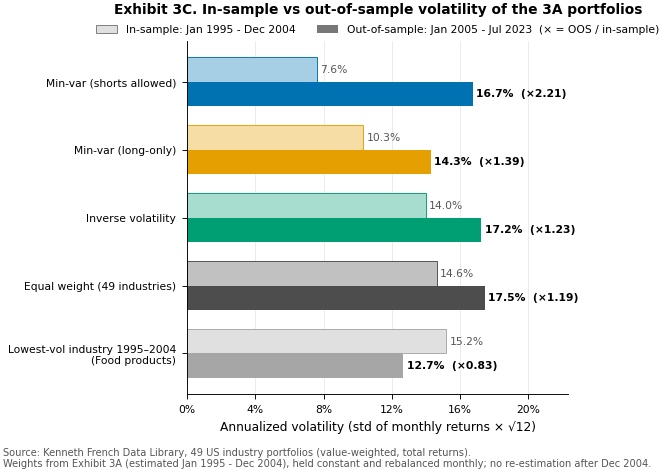

In [9]:
names = [p3.SHORT_LABELS[k].replace("\n", " ") for k in W.columns]
v_in, v_out = list(vol_in.to_numpy()), list(vol_oos.to_numpy())
cols = [p3.PF_COLORS[k] for k in W.columns]
if SHOW_REFERENCE:
    names += ["Equal weight (49 industries)", f"Lowest-vol industry 1995–2004\n({EN[low_ind]})"]
    v_in += list(ref["样本内 1995–2004"]); v_out += list(ref["样本外 2005–2023"])
    cols += [config.COLOR_MARKET, "#A6A6A6"]

def lighten(c, a=0.35):
    return mcolors.to_hex(a * np.array(mcolors.to_rgb(c)) + (1 - a))

fig, ax = utils.new_fig("tall")
y = np.arange(len(names))[::-1] * 1.0
h = 0.36
ax.barh(y + h / 2, v_in, height=h, color=[lighten(c) for c in cols], edgecolor=cols, linewidth=0.6)
ax.barh(y - h / 2, v_out, height=h, color=cols)
for yi, a, b in zip(y, v_in, v_out):
    ax.text(a + 0.002, yi + h / 2, f"{a:.1%}", va="center", fontsize=config.FONT_SMALL, color="#555555")
    ax.text(b + 0.002, yi - h / 2, f"{b:.1%}  (×{b / a:.2f})", va="center", fontsize=config.FONT_SMALL,
            fontweight="bold")
ax.set_yticks(y, names)
ax.set_xlim(0, max(v_in + v_out) * 1.28)
utils.percent_axis(ax, "x")
ax.set_xlabel("Annualized volatility (std of monthly returns × √12)")
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator
ax.xaxis.set_major_locator(MultipleLocator(0.04))
ax.legend(handles=[Patch(facecolor="#E0E0E0", edgecolor="#777777", linewidth=0.6, label="In-sample: Jan 1995 - Dec 2004"),
                   Patch(facecolor="#777777", label="Out-of-sample: Jan 2005 - Jul 2023  (× = OOS / in-sample)")],
          loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, borderaxespad=0.2)
ax.set_title("Exhibit 3C. In-sample vs out-of-sample volatility of the 3A portfolios", pad=18)
src = (p3.SOURCE_FF49 + "\nWeights from Exhibit 3A (estimated Jan 1995 - Dec 2004), held constant and rebalanced "
       "monthly; no re-estimation after Dec 2004.")
print("PNG →", utils.save_fig(fig, "fig_3C_oos_vol", source=src).relative_to(p3.ROOT))
plt.show()

### 8.2 辅助图：滚动 36 个月波动率

把样本外期间每个时点"过去 36 个月"的年化波动率画出来，看排序是不是**一直**如此，而不只是整段平均的结果。为保证每个窗口都完全落在样本外，曲线从 2007/12 开始（第一个完整的 36 个月窗口）。阴影是 2008/09–2009/02 金融危机和 2020/02–03 新冠疫情（3E 会用到的两段危机）。

PNG → output/figures/fig_3C_rolling_vol.png
在 188 个滚动窗口中，只做多最小方差是三者最低的比例：85%


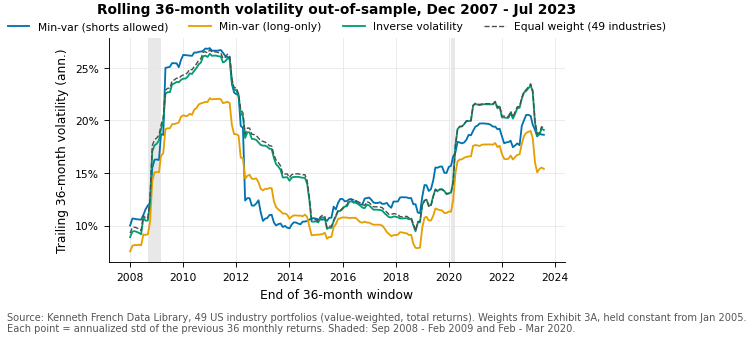

In [10]:
WIN = 36
roll = R_oos.rolling(WIN).std() * np.sqrt(12)
roll_ew = oos.mean(axis=1).rolling(WIN).std() * np.sqrt(12)
roll, roll_ew = roll.dropna(), roll_ew.dropna()
x = roll.index.to_timestamp(how="end")

fig, ax = utils.new_fig("full")
for k in W.columns:
    ax.plot(x, roll[k], color=p3.PF_COLORS[k], label=COLS[k])
if SHOW_REFERENCE:
    ax.plot(x, roll_ew, color=config.COLOR_MARKET, linestyle="--", linewidth=0.9, label="Equal weight (49 industries)")
for a, b in [("2008-09", "2009-02"), ("2020-02", "2020-03")]:
    ax.axvspan(pd.Period(a, "M").to_timestamp(), pd.Period(b, "M").to_timestamp(how="end"), color="#D9D9D9", alpha=0.6, lw=0)
utils.percent_axis(ax, "y")
ax.set_ylabel("Trailing 36-month volatility (ann.)")
ax.set_xlabel("End of 36-month window")
from matplotlib.ticker import MultipleLocator
ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.set_title("Rolling 36-month volatility out-of-sample, Dec 2007 - Jul 2023", pad=16)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4, borderaxespad=0.2)
src = (p3.SOURCE_FF49 + " Weights from Exhibit 3A, held constant from Jan 2005.\n"
       "Each point = annualized std of the previous 36 monthly returns. Shaded: Sep 2008 - Feb 2009 and Feb - Mar 2020.")
print("PNG →", utils.save_fig(fig, "fig_3C_rolling_vol", source=src).relative_to(p3.ROOT))
share = (roll["mv_long_only"] < roll[["mv_short", "inverse_vol"]].min(axis=1)).mean()
print(f"在 {len(roll)} 个滚动窗口中，只做多最小方差是三者最低的比例：{share:.0%}")
plt.show()

## 9. 写报告时的要点

> 下面的数字来自本 notebook 的运行结果（数据固定，重跑结果不变）。

### 结果速览

| 组合 | 样本内 1995–2004 | 样本外 2005–2023/07 | 样本外 / 样本内 | 排名变化 |
|---|---|---|---|---|
| 最小方差（可做空） | 7.6% | 16.7% | **×2.21** | 1 → **2** |
| 最小方差（只做多） | 10.3% | **14.3%** | ×1.39 | 2 → **1** |
| 逆波动率 | 14.0% | 17.2% | ×1.23 | 3 → 3 |
| *参照：49 个行业等权* | *14.6%* | *17.5%* | *×1.19* | – |
| *参照：1995–2004 波动最低的单个行业（食品）* | *15.2%* | *12.7%* | *×0.83* | – |

### 可以写进报告的观察

1. **样本外最低的是只做多最小方差（14.3%），最高的是逆波动率（17.2%）**。可做空组合从样本内第一掉到第二（16.7%），只比逆波动率低 0.5 个百分点，几乎回到"什么都不做"的水平（等权 17.5%）。
2. **顺序部分符合预期**：
    - 符合：三个组合仍然都比等权组合稳，逆波动率仍然最高；
    - 不符合"天真"的预期：样本内最低的可做空组合没能保持第一。但从课上讲的优化理论看，这正是**应当预期**的结果。
3. **原因一：优化器放大估计误差（error maximization）**。用到的信息越多，"水分"越大，样本外/样本内比值正好按这个顺序排列：可做空 ×2.21 > 只做多 ×1.39 > 逆波动率 ×1.23 > 等权 ×1.19。可做空组合有 4.7 倍的总杠杆（多头 284%、空头 184%），它在样本内依靠多头腿和空头腿高度相关（0.98）来互相抵消波动。到了样本外，这个相关性只降到 0.965，看起来变化很小，但在 4.7 倍杠杆下被放大，波动率翻了一倍多。
4. **原因二：只做多约束起到了"正则化"作用**。不允许做空，就限制了优化器去押注那些不稳定的对冲关系，相当于对协方差估计做了收缩（shrinkage）。这是一个文献里有名的结论：Jagannathan and Ma (2003, *Journal of Finance*) 指出，即使这个约束"本身是错的"，也能降低样本外风险。
5. **原因三：市场环境变了（协方差不是恒定的）**。行业两两相关系数的平均值从样本内的 0.40 升到样本外的 0.59（2008 年金融危机、2020 年新冠疫情时各行业同跌），而单个行业的波动率中位数几乎没变（21.9% → 21.8%）。所以样本外波动普遍上升，主要是**分散化的效果变弱了**，不是行业本身变得更不稳定。
6. **结论稳健**：分成 2005–2014、2015–2023/07、金融危机前（2005–2007）、金融危机期间（2008–2009）四段来看，只做多最小方差在每一段都是三者最低；在 188 个滚动 36 个月窗口中，它有 85% 的时间是最低的。可做空组合在金融危机期间（2008–2009）的波动（31.6%）甚至**高于等权组合**（29.0%），说明多空对冲恰恰在最需要的时候失效了。
7. **一个值得诚实指出的发现**：如果在 2004 年底只买入当时最稳的单个行业（食品），样本外波动只有 12.7%，比三个组合都低。说明在这段时期，"选对防御行业"比"精细优化"更有效，这也呼应了题目脚注 3（De Boer 等，2014）关于低波动投资可以通过行业配置实现的观点。不过单一行业的集中风险很大，这个结果有运气成分，报告里可以作为补充，不宜作为主结论。

### 英文写法参考（可改写进报告）

> Out-of-sample (Jan 2005 – Jul 2023), the long-only minimum-variance portfolio has the lowest realized volatility (14.3% p.a.), followed by the minimum-variance portfolio with shorts allowed (16.7%) and the inverse-volatility portfolio (17.2%); the equally weighted portfolio has 17.5%. The unconstrained portfolio, best in-sample at 7.6%, sees its volatility more than double (×2.21), while the deterioration is progressively smaller for the long-only (×1.39) and inverse-volatility (×1.23) portfolios. This is consistent with what we discussed on optimization: the more freely the optimizer uses the estimated covariance matrix, the more it fits estimation error. With 4.7× gross leverage, small changes in the correlation between its long and short legs translate into large changes in risk. The long-only constraint acts as a form of shrinkage (Jagannathan and Ma, 2003), which is why the constrained portfolio is the most robust out-of-sample. Rising cross-industry correlations after 2004 (average pairwise correlation 0.40 → 0.59) reduced the diversification benefit for all portfolios. The ranking holds in every sub-period and in 85% of rolling 36-month windows.

### 备注

- 参照组不是题目要求的；不想放的话把第 5 节的 `SHOW_REFERENCE` 改成 `False` 再重跑；
- 主图 `fig_3C_oos_vol.png` 同时展示了样本内和样本外，报告里可以用这一张图同时覆盖 3B 和 3C，节省篇幅（8 页限制）；
- 滚动波动率图是辅助图，放不放进报告由你决定。